**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the `notebooks/` folder.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/StatsBook-GitBook.git statsbook')
        os.system('git -C statsbook sparse-checkout set notebooks/Data notebooks/Support')
    path = 'statsbook/notebooks/'

Data for the Gibbs reactor (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $P$ | `P` | pressure [bar] |
| $T$ | `T` | temperature [K] |
| $\xi$ | `xi` | conversion [-] |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Each file has columns $(T, P, \xi)$; we stack the high- and low-temperature data
and add a little noise to blur the pattern, as in measured data.

In [3]:
data_high = pd.read_csv(path+'Data/gibbs_hightemp_class.dat', sep="\t", header=None)
data_low = pd.read_csv(path+'Data/gibbs_lowtemp_class.dat', sep="\t", header=None)
data = pd.concat([data_high, data_low])
n = len(data)

np.random.seed(1)  # reproducibility
T = data.iloc[:, 0].to_numpy() + np.random.randn(n)*0.1    # temperature
P = data.iloc[:, 1].to_numpy() + np.random.randn(n)*0.1    # pressure
xi = data.iloc[:, 2].to_numpy() + np.random.randn(n)*0.1   # conversion

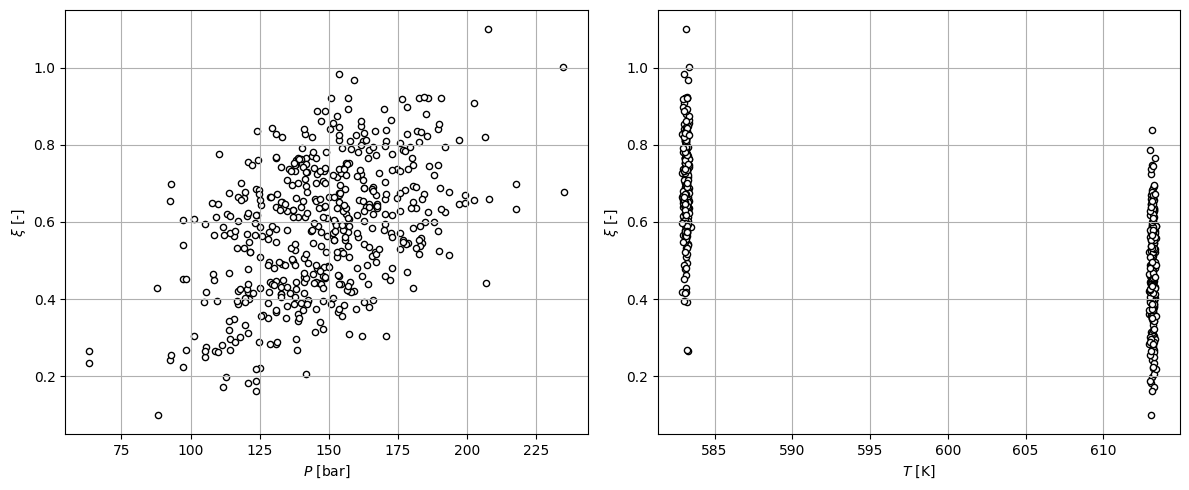

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(P, xi, marker='o', s=20, color='white', edgecolor='black')
axs[0].set_xlabel('$P$ [bar]')
axs[0].set_ylabel(r'$\xi$ [-]')
axs[0].grid(True)
axs[1].scatter(T, xi, marker='o', s=20, color='white', edgecolor='black')
axs[1].set_xlabel('$T$ [K]')
axs[1].set_ylabel(r'$\xi$ [-]')
axs[1].grid(True)
plt.tight_layout()
plt.show()